# Wideband Timing using `PINT`

**Pulsar :** J1909-3744 (testing)

**User :** Churchil

In [227]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import os
import time
import pandas as pd
import scipy as sp
import pint
from pint.logging import setup
from pint.residuals import Residuals
from pint.fitter import WidebandDownhillFitter
import astropy.units as u
from datetime import date

_ = setup(level='ERROR')

%matplotlib inline
%config IPython.matplotlib.backend = "retina"
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams["savefig.dpi"] = 300
rcParams["figure.dpi"] = 300

In [232]:
psrname = f'PSR'
parfile = f'./sample.v3.par'
timfile = f'./sample.v3.tim'

print(f'\nPulsar Name : {psrname}\n')
print(f'Input par file : {parfile}\n')
print(f'Input tim file : {timfile}\n')


Pulsar Name : PSR

Input par file : ./sample.v3.par

Input tim file : ./sample.v3.tim



In [233]:
# Creating the Timing Model and ToA objects
psr_model, psr_toas = pint.models.get_model_and_toas(parfile, timfile, 
                                                     allow_T2=True, allow_tcb=True, 
                                                     planets=True)

toas = psr_toas.get_mjds()
toaerrs = psr_toas.get_errors()
dms = psr_toas.get_dms()
dmerrs = psr_toas.get_dm_errors()
Tspan_years = psr_toas.get_Tspan().to(u.year)

print(f'\nTime baseline of PSR {psrname} = {Tspan_years:.2f} years')
print(f'\nMedian ToA error : {np.median(toaerrs):.4f}')
print(f'\nMedian DM error : {np.median(dmerrs):.6f}')


Time baseline of PSR PSR = 21.90 yr years

Median ToA error : 1.0000 us

Median DM error : 0.000050 dmu


In [234]:
# At this stage, all params should have Frozen=True (i.e. no parameter is being fitted)
psr_model

TimingModel(
  AbsPhase(
    MJDParameter(   TZRMJD              59000.7501875472080439 (d) frozen=True),
    strParameter(   TZRSITE             ssb               frozen=True),
    floatParameter( TZRFRQ              inf               (MHz) frozen=True)),
  AstrometryEquatorial(
    MJDParameter(   POSEPOCH            58999.9997541495914071 (d) frozen=True),
    floatParameter( PX                  0.9265877399482784 (mas) +/- 0.017299541922065124 mas frozen=True),
    floatParameter( VLBIAX              UNSET,
    floatParameter( VLBIAY              UNSET,
    floatParameter( VLBIAZ              UNSET,
    AngleParameter( RAJ                 19:09:47.42478610 (hourangle) +/- 0h00m00s frozen=True),
    AngleParameter( DECJ                -37:44:14.90762000 (deg) +/- 0d00m00.00000001s frozen=True),
    floatParameter( PMRA                -9.523838244357327 (mas / yr) +/- 0.0014307968697203105 mas / yr frozen=True),
    floatParameter( PMDEC               -35.78203337899618 (mas / yr) +/

Plotting the original ToA residuals



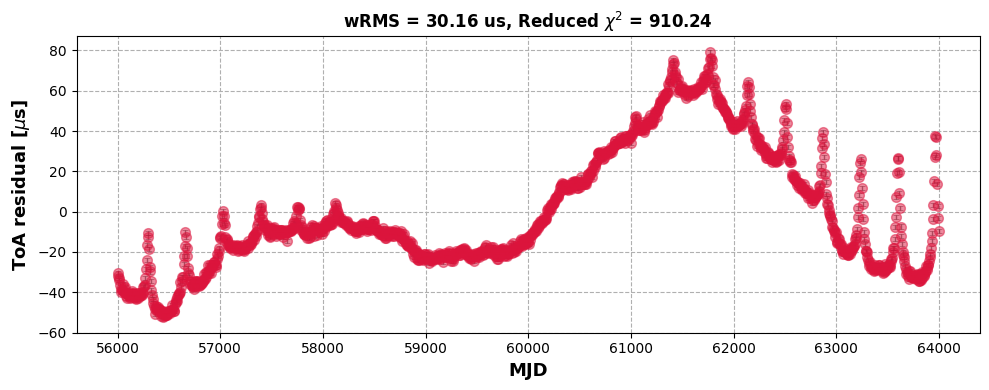

In [235]:
# Generating the pre-timing residuals
combined_timing_resids = Residuals(psr_toas, psr_model)
prenoise_timing_resids = Residuals(psr_toas, psr_model, residual_type='toa')
prenoise_dm_resids = Residuals(psr_toas, psr_model, residual_type='dm')

print(f'Plotting the original ToA residuals\n')
fig = plt.figure(figsize=(10, 4), dpi=100)
plt.errorbar(toas, prenoise_timing_resids.time_resids.to(u.us), yerr=toaerrs, fmt='o', ms=7, c='crimson', alpha=0.5, \
             elinewidth=1.0, capsize=2, capthick=0.5, ecolor='k')
plt.ticklabel_format(useOffset=False)
plt.grid(ls='dashed')
plt.xlabel(f'MJD', fontweight='bold', fontsize=13)
plt.ylabel(rf'ToA residual [$\mu$s]', fontweight='bold', fontsize=13)
# fig.suptitle(f'{psrname} pre-timing ToA residuals', fontweight='bold', fontsize=16)
plt.title(rf'wRMS = {prenoise_timing_resids.rms_weighted():.2f}, '+
          rf'Reduced $\chi^2$ = {combined_timing_resids.reduced_chi2:.2f}', fontweight='bold')
plt.tight_layout()
# plt.savefig(f'{outdir}/{psrname}.pre-timing.ToAres.pdf')

Plotting the original DM residuals



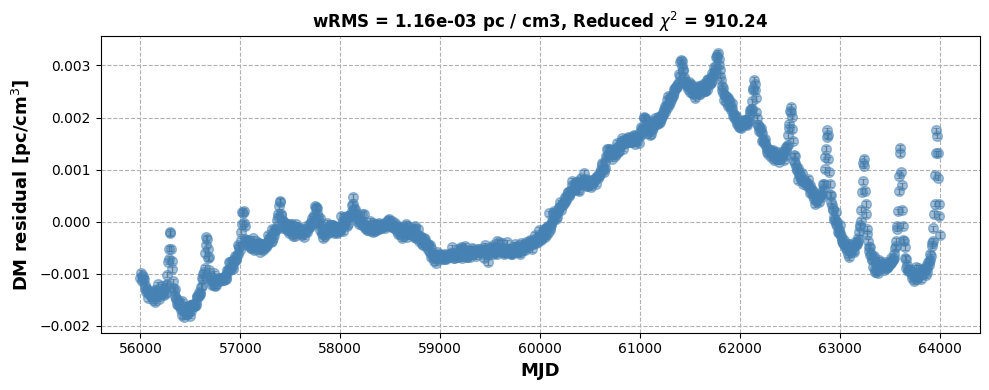

In [236]:
print(f'Plotting the original DM residuals\n')
fig = plt.figure(figsize=(10, 4), dpi=100)
plt.errorbar(toas, prenoise_dm_resids.resids, yerr=dmerrs, fmt='o', ms=7, c='steelblue', alpha=0.5, \
             elinewidth=1.0, capsize=2, capthick=0.5, ecolor='k')
plt.ticklabel_format(useOffset=False)
plt.grid(ls='dashed')
plt.xlabel(f'MJD', fontweight='bold', fontsize=13)
_ = plt.ylabel(rf'DM residual [pc/cm$^3$]', fontweight='bold', fontsize=13)
# fig.suptitle(f'{psrname} pre-timing DM residuals', fontweight='bold', fontsize=16)
plt.title(rf'wRMS = {prenoise_dm_resids.rms_weighted():.2e}, '+
          rf'Reduced $\chi^2$ = {combined_timing_resids.reduced_chi2:.2f}', fontweight='bold')
plt.tight_layout()
# plt.savefig(f'{outdir}/{psrname}.pre-timing.DMres.pdf')

In [549]:
def generate_dmx_parfile(toas, binsize, parfile, newparfile, fitflags=True):
    '''
        Function to generate DMXs with a given bin size for a given set of MJDs
    '''
    if toas.unit:
        toas = toas.value

    cadence = int(toas[1]-toas[0])
    if binsize < cadence:
        raise ValueError(f'Cannot have DMX bins lesser than data cadence')
    
    ranges = np.arange(toas[0], toas[-1], binsize, dtype=int)
    if ranges.size < 1000:
        idxs = [str(i+1).zfill(len(f'X{ranges.size}')) for i in range(ranges.size)]
    elif 1000 <= ranges.size < 9999:
        idxs = [str(i+1).zfill(len(f'{ranges.size}')) for i in range(ranges.size)]
    else:
        raise KeyError(f'DMX keywords with more than 4 digits cannot be parsed')
    if fitflags:
        DMX = [f'DMX_{idx} 0.0 1 0.0' for idx in idxs]
    else:
        DMX = [f'DMX_{idx} 0.0 0.0' for idx in idxs]
    
    DMXR1 = [f'DMXR1_{idx} {val+0.0001:.4f}' if index else f'DMXR1_{idx} {val:.4f}' for idx, (index, val) in zip(idxs, enumerate(ranges))]
    DMXR2 = [f'DMXR2_{idx} {val:.4f}' for idx, (index, val) in zip(idxs[:-1], enumerate(ranges[1:]))]
    DMXR2.append(f'DMXR2_{idxs[-1]} {toas[-1]:.4f}')
    DMXEP = [f'DMXEP_{idx} {(float(val1.split()[-1])+float(val2.split()[-1]))/2:.4f}' for idx, val1, val2 in zip(idxs, DMXR1, DMXR2)]
    
    parlines = [f for f in open(parfile, 'r').readlines()]
    newpar = open(newparfile, 'w+')
    for line in parlines:
        newpar.write(line)
    for dmx, dmxr1, dmxr2 in zip(DMX, DMXR1, DMXR2):
        line = f'{dmxr1} \n'
        line += f'{dmx} \n'
        line += f'{dmxr2} \n'
        newpar.write(line)
    newpar.close()

    return DMX, DMXR1, DMXR2, DMXEP

In [550]:
toas

<Quantity [56000.00000001, 56006.00150037, 56012.00300075, ...,
           63987.99699925, 63993.99849962, 63999.99999998] d>

In [551]:
newparfile = f'./{psrname}.DMX.par'
DMXs, DMXR1s, DMXR2s, DMXEPs = generate_dmx_parfile(toas, binsize=15, parfile=parfile, newparfile=newparfile, fitflags=True)

In [552]:
# Creating the Timing Model and ToA objects
psr_model, psr_toas = pint.models.get_model_and_toas(newparfile, timfile, 
                                                     allow_T2=True, allow_tcb=True, 
                                                     planets=True)

toas = psr_toas.get_mjds()
toaerrs = psr_toas.get_errors()
dms = psr_toas.get_dms()
dmerrs = psr_toas.get_dm_errors()
Tspan_years = psr_toas.get_Tspan().to(u.year)

print(f'\nTime baseline of PSR {psrname} = {Tspan_years:.2f} years')
print(f'\nMedian ToA error : {np.median(toaerrs):.4f}')
print(f'\nMedian DM error : {np.median(dmerrs):.6f}')


Time baseline of PSR PSR = 21.90 yr years

Median ToA error : 1.0000 us

Median DM error : 0.000050 dmu


Plotting the original ToA residuals



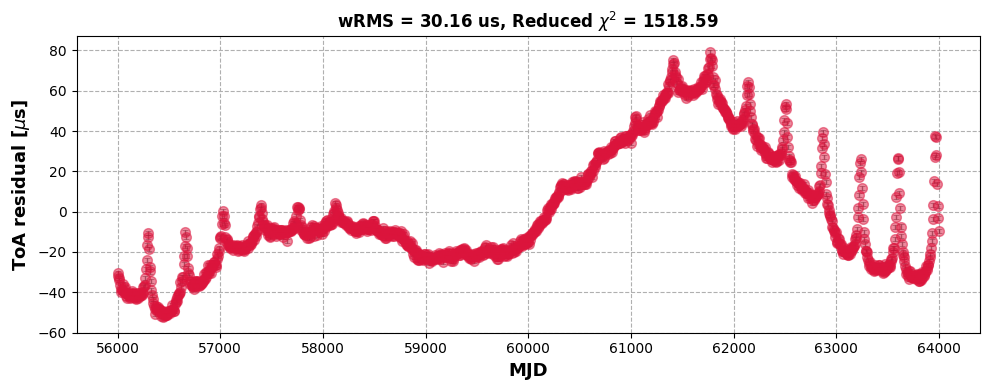

In [553]:
# Generating the pre-timing residuals
combined_timing_resids = Residuals(psr_toas, psr_model)
prenoise_timing_resids = Residuals(psr_toas, psr_model, residual_type='toa')
prenoise_dm_resids = Residuals(psr_toas, psr_model, residual_type='dm')

print(f'Plotting the original ToA residuals\n')
fig = plt.figure(figsize=(10, 4), dpi=100)
plt.errorbar(toas, prenoise_timing_resids.time_resids.to(u.us), yerr=toaerrs, fmt='o', ms=7, c='crimson', alpha=0.5, \
             elinewidth=1.0, capsize=2, capthick=0.5, ecolor='k')
plt.ticklabel_format(useOffset=False)
plt.grid(ls='dashed')
plt.xlabel(f'MJD', fontweight='bold', fontsize=13)
plt.ylabel(rf'ToA residual [$\mu$s]', fontweight='bold', fontsize=13)
# fig.suptitle(f'{psrname} pre-timing ToA residuals', fontweight='bold', fontsize=16)
plt.title(rf'wRMS = {prenoise_timing_resids.rms_weighted():.2f}, '+
          rf'Reduced $\chi^2$ = {combined_timing_resids.reduced_chi2:.2f}', fontweight='bold')
plt.tight_layout()
# plt.savefig(f'{outdir}/{psrname}.pre-timing.ToAres.pdf')

Plotting the original DM residuals



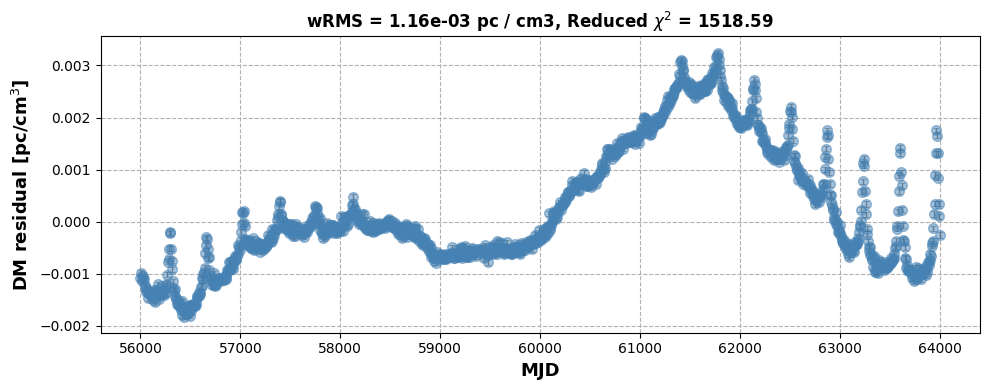

In [554]:
print(f'Plotting the original DM residuals\n')
fig = plt.figure(figsize=(10, 4), dpi=100)
plt.errorbar(toas, prenoise_dm_resids.resids, yerr=dmerrs, fmt='o', ms=7, c='steelblue', alpha=0.5, \
             elinewidth=1.0, capsize=2, capthick=0.5, ecolor='k')
plt.ticklabel_format(useOffset=False)
plt.grid(ls='dashed')
plt.xlabel(f'MJD', fontweight='bold', fontsize=13)
_ = plt.ylabel(rf'DM residual [pc/cm$^3$]', fontweight='bold', fontsize=13)
# fig.suptitle(f'{psrname} pre-timing DM residuals', fontweight='bold', fontsize=16)
plt.title(rf'wRMS = {prenoise_dm_resids.rms_weighted():.2e}, '+
          rf'Reduced $\chi^2$ = {combined_timing_resids.reduced_chi2:.2f}', fontweight='bold')
plt.tight_layout()
# plt.savefig(f'{outdir}/{psrname}.pre-timing.DMres.pdf')


Timing the ToAs and DMs using PINT...

ToA residual wRMS pre-fit = 30.16 us

ToA residual wRMS post-fit = 1.59 us

DM residual wRMS pre-fit = 1.16e-03 pc / cm3

DM residual wRMS post-fit = 7.12e-05 pc / cm3

Saving the results in ./PSR.DMX.fitted.par


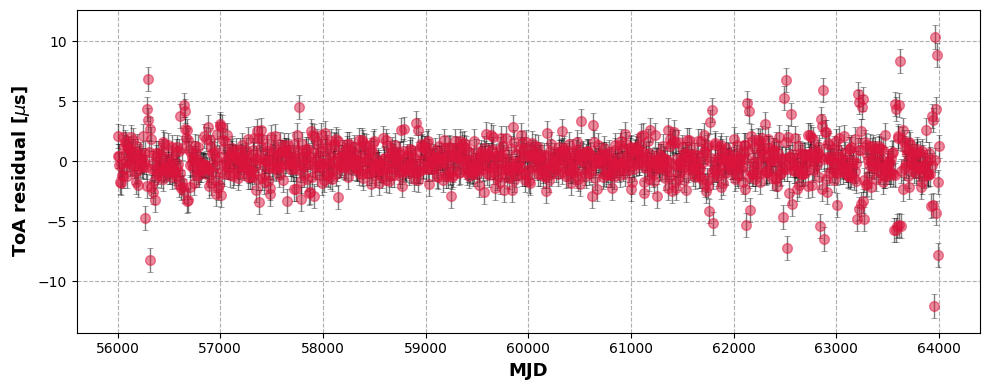

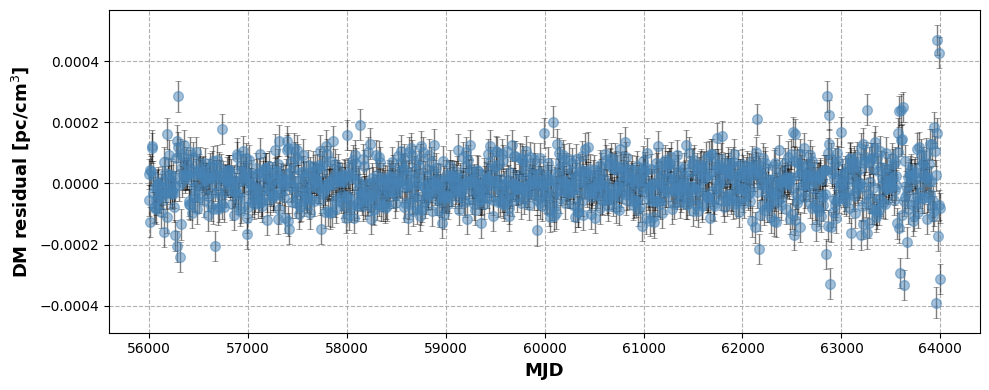

In [555]:
print(f'\nTiming the ToAs and DMs using PINT...')
fitted_parfile = f'./{psrname}.DMX.fitted.par'

# The Timing Model is updated as per the fitted parameters
fitter_obj = WidebandDownhillFitter(psr_toas, psr_model)
fitter_obj.fit_toas(maxiter=100000)

fig = plt.figure(figsize=(10, 4), dpi=100)
plt.errorbar(fitter_obj.resids.toas.get_mjds(), fitter_obj.resids.toa.calc_time_resids()/1e-6, 
             yerr=toaerrs/1e-6, fmt='o', ms=7, c='crimson', alpha=0.5, \
             elinewidth=1.0, capsize=2, capthick=0.5, ecolor='k')
plt.ticklabel_format(useOffset=False)
plt.grid(ls='dashed')
plt.xlabel(f'MJD', fontweight='bold', fontsize=13)
plt.ylabel(rf'ToA residual [$\mu$s]', fontweight='bold', fontsize=13)
plt.tight_layout()

fig = plt.figure(figsize=(10, 4), dpi=100)
plt.errorbar(fitter_obj.resids.toas.get_mjds(), fitter_obj.resids.dm.calc_resids(), 
             yerr=dmerrs, fmt='o', ms=7, c='steelblue', alpha=0.5, \
             elinewidth=1.0, capsize=2, capthick=0.5, ecolor='k')
plt.ticklabel_format(useOffset=False)
plt.grid(ls='dashed')
plt.xlabel(f'MJD', fontweight='bold', fontsize=13)
_ = plt.ylabel(rf'DM residual [pc/cm$^3$]', fontweight='bold', fontsize=13)
plt.tight_layout()

# The reduced chi-square should be calculated for the global fit
combined_timing_resids_fitted = fitter_obj.resids
prenoise_timing_resids_fitted = fitter_obj.resids.toa
prenoise_dm_resids_fitted = fitter_obj.resids.dm

print(f'\nToA residual wRMS pre-fit = {prenoise_timing_resids.rms_weighted():.2f}')
print(f'\nToA residual wRMS post-fit = {prenoise_timing_resids_fitted.rms_weighted():.2f}')
print(f'\nDM residual wRMS pre-fit = {prenoise_dm_resids.rms_weighted():.2e}')
print(f'\nDM residual wRMS post-fit = {prenoise_dm_resids_fitted.rms_weighted():.2e}')

print(f'\nSaving the results in {fitted_parfile}')
fitter_obj.model.write_parfile(fitted_parfile)

In [557]:
def write_DMX_timeseries(DMXs, DMXR1s, DMXR2s, DMXEPs, outfile, fitter_obj=None, DMXparfile=None):
    '''
        Function to provide the DMX time series from a PINT fitter object or a DMX par file
    '''
    dmxpars, dmxvals, dmxerrs = [], [], []
    if fitter_obj:
        for dmx in DMXs:
            param = dmx.split()[0]
            dmxpars.append(param)
            dmxvals.append(fitter_obj.get_fitparams()[param].value)
            dmxerrs.append(fitter_obj.get_fitparams()[param].uncertainty.value)
    elif DMXparfile:
        raise NotImplementedError(f'The configuration is not yet present')
    else:
        raise ValueError(f'Either a PINT fitter object or DMX par file should be provided')
        
    file = open(outfile, 'w+')
    file.write(f'# Fiducial DM = {fitter_obj.get_allparams()['DM'].value}\n')
    file.write(f'# DMX parameters\n')
    for dmx, dmxval, dmxerr in zip(dmxpars, dmxvals, dmxerrs):
        file.write(f'{dmx} {dmxval} {dmxerr}\n')
    file.write(f'# DMX ranges\n')
    for dmxr1, dmxep, dmxr2 in zip(DMXR1s, DMXEPs, DMXR2s):
        file.write(f'{dmxr1}\n')
        file.write(f'{dmxep}\n')
        file.write(f'{dmxr2}\n')
    file.close()

    return dmxpars, dmxvals, dmxerrs

In [558]:
outfile = f'./{psrname}.DMXs.txt'
DMXpars, DMXvals, DMXerrs = write_DMX_timeseries(DMXs, DMXR1s, DMXR2s, DMXEPs, outfile, fitter_obj=fitter_obj)
cov = fitter_obj.parameter_covariance_matrix
import pandas as pd
idxlabels = [label[0] for label in cov.labels[0][1:]]
matrix = cov.matrix[1:, 1:]
df = pd.DataFrame(matrix, index=idxlabels, columns=idxlabels)
df.to_csv(f'./{psrname}.DMXcovs.csv', index=True)

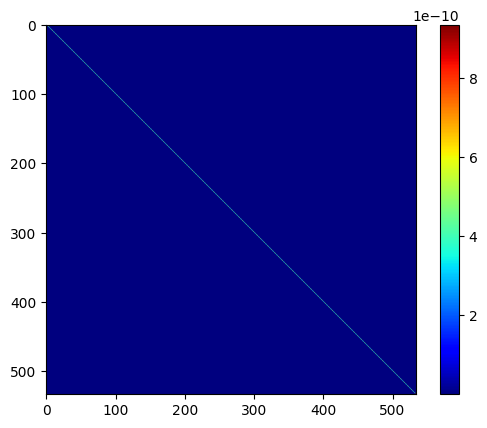

In [559]:
plt.figure(dpi=100)
c = plt.imshow(matrix, cmap='jet')
plt.colorbar(c)

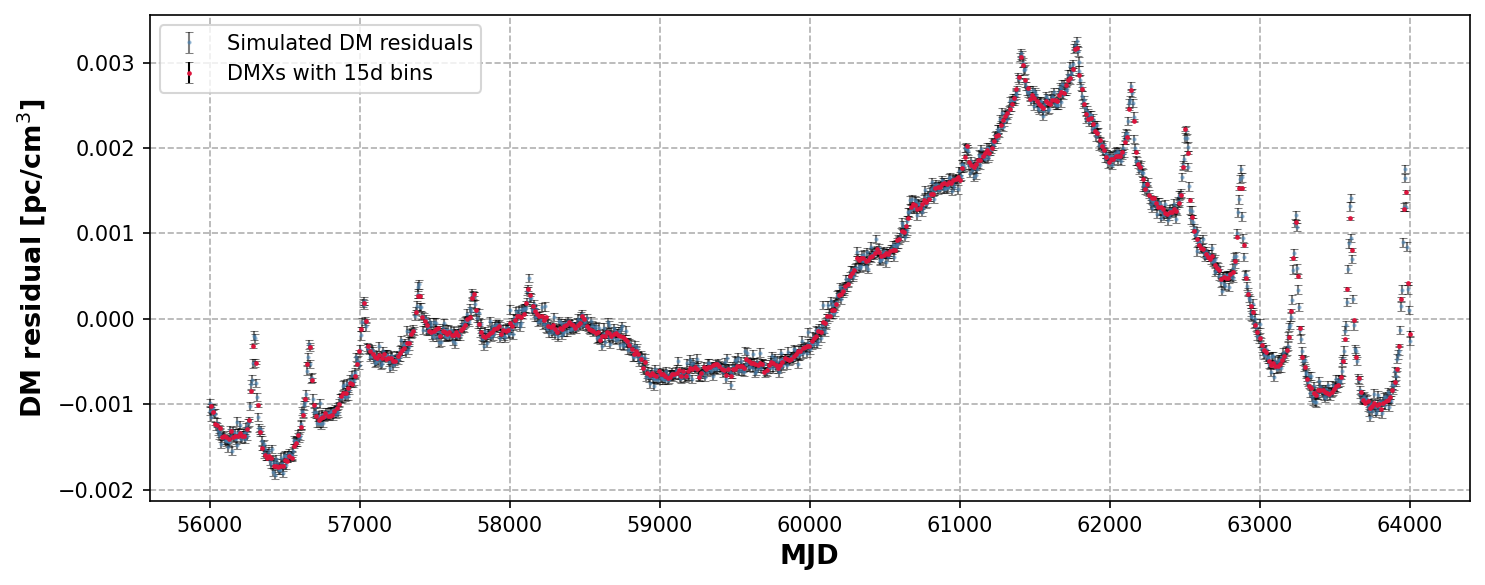

In [564]:
fig, ax = plt.subplots(figsize=(10, 4), dpi=150)
ax.errorbar(toas, prenoise_dm_resids.resids, yerr=dmerrs, fmt='o', ms=1.0, c='steelblue', alpha=0.5, 
            elinewidth=1.0, capsize=2, capthick=0.5, ecolor='k', label='Simulated DM residuals')
ax.errorbar([float(f.split()[-1]) for f in DMXEPs], DMXvals, yerr=DMXerrs, fmt='o', ms=1.25, c='crimson', 
            elinewidth=1.0, capsize=2, capthick=0.25, ecolor='k', label=f'DMXs with {binsize}d bins')
plt.legend(loc='upper left')
plt.ticklabel_format(useOffset=False)
plt.grid(ls='dashed')
plt.xlabel(f'MJD', fontweight='bold', fontsize=13)
_ = plt.ylabel(rf'DM residual [pc/cm$^3$]', fontweight='bold', fontsize=13)
plt.tight_layout()

## F-test to check for parameter significance

**NOTE :** This section needs to be iteratively run in order to arrive at the best set of timing model parameters.

- Usually, we begin with the `Spindown` parameters, i.e., `F0` and `F1`, which change most rapidly.
- If the binary is too tight, i.e., `PB` is too small, then we can fit for that in the next step.
- The ISM variations are expected to happen faster than the remaining effects, so the `DispersionDM` and `SolarWindDispersion` parameters should be fitted in the next step.
- If the pulsar has a very high proper motion, then `Astrometry` parameters should be fitted before the `Binary` parameters.
- If the above does not hold, then `Binary` parameters should be fitted after ISM ones.
- After all that, the `Astrometry` parameters should be fitted in the next step.
- The `PX` changes on very long time scales, so it should be fitted after all the above parameters are checked.

For the time baseline of about 6 to 7 years (for DR1 pulsars) we do not expect the `Astrometry` parameters or even some secular `Binary` parameters such as `H3` and `STIG` to change significantly. Therefore, whatever parameters are fitted, care should be taken to properly inspect the covariances and the choice of fitting the parameters also relies on the physical motivation depending on the pulsar.

In [7]:
# # List of components in the Timing Model
# print(f'List of components in the Timing Model : \n')
# for component in psr_model.components.keys():
#     print(psr_model.components[component])

In [9]:
# List of params that can be fitted in the Timing Model
print(f'List of parameters that can be fitted in the Timing Model :\n')
for param in psr_model.fittable_params:
    print(psr_model[param])

List of parameters that can be fitted in the Timing Model :

floatParameter( PX                  0.9265877399482784 (mas) +/- 0.017299541922065124 mas frozen=True)
AngleParameter( RAJ                 19:09:47.42478610 (hourangle) +/- 0h00m00s frozen=True)
AngleParameter( DECJ                -37:44:14.90762000 (deg) +/- 0d00m00.00000001s frozen=True)
floatParameter( PMRA                -9.523838244357327 (mas / yr) +/- 0.0014307968697203105 mas / yr frozen=True)
floatParameter( PMDEC               -35.78203337899618 (mas / yr) +/- 0.004888366424279205 mas / yr frozen=True)
floatParameter( F0                  339.3156919215502673 (Hz) +/- 8.90697670426446e-13 Hz frozen=True)
floatParameter( F1                  -1.6148086912549433248e-15 (Hz / s) +/- 6.358438209829713e-21 Hz / s frozen=True)
floatParameter( NE_SW               0.0               (1 / cm3) frozen=True)
floatParameter( NE_SW1              0.0               (1 / (yr cm3)) frozen=True)
floatParameter( SWP                 2.0  

In [9]:
# Creating a fitter object with the original timing solution (without any fit)
fitter_obj = WidebandDownhillFitter(psr_toas, psr_model)
timing_maxiter = 100000
comment = f'Changelog :'
comment += f'\nReduced chi-square pre-fit = {combined_timing_resids.reduced_chi2:.4f}'
print(comment)

Changelog :
Reduced chi-square pre-fit = 8381.5629


In [10]:
# Comment about the fit done
datestamp = date.today()

try:
    paramnames = ['F0', 'F1', 'DM', 'NE_SW', 'NE_SW1']
    parameters = [psr_model[pname] for pname in paramnames]
    components = [param._parent for param in parameters]
    
    ftest = fitter_obj.ftest(parameter=parameters, component=components, 
                             maxiter=timing_maxiter, full_output=True)
    
    print(f"F-statistic of fit : {ftest['ft']:.4e}")
    print(f"Weighted RMS of ToA residuals after fit : {ftest['resid_wrms_test']:.4e}")
    print(f"Weighted RMS of DM residuals after fit : {ftest['dm_resid_wrms_test']:.4e}")
    print(f"Reduced chi-square after fit : {(ftest['chi2_test']/ftest['dof_test']):.4f}")
    comment += f"\n- {datestamp} : Ftest for {paramnames}, reduced chi-square post-fit = {(ftest['chi2_test']/ftest['dof_test']):.4f}"
    
    # Covariance matrix for the fit
    for pname in paramnames:
        fitter_obj.model[pname].frozen = False
        
    fitter_obj.fit_toas(maxiter=timing_maxiter)
    
    # Covariance matrix of the parameters after fitting
    print(fitter_obj.parameter_covariance_matrix)
    
    # Correlation matrix of the parameters after fitting
    print(fitter_obj.parameter_correlation_matrix)

except RecursionError:
    print(f'The above choice of parameters did not improve the fitting.')
    print(f'Add parameters in this (generic) order : Spindown > DispersionDM = SolarWindDispersion > Binary > Astrometry')
    comment += f"\n- {datestamp} : Ftest for {paramnames}, no improvement in the fit"

print(f'Reseting the timing model to its original state')
fitter_obj.reset_model()

F-statistic of fit : 6.9238e-121
Weighted RMS of ToA residuals after fit : 1.9025e+00 us
Weighted RMS of DM residuals after fit : 2.1409e-04 pc / cm3
Reduced chi-square after fit : 624.3042

Parameter covariance matrix:
               F0         F1        NE_SW     NE_SW1       DM     
    F0       6.657e-26
    F1      -9.196e-34  1.456e-41
   NE_SW     3.433e-18  7.393e-24  4.062e-04
  NE_SW1     5.865e-16  9.621e-24  1.253e-04  3.353e-04
    DM      -8.453e-21  9.090e-29 -4.905e-09 -3.319e-11  8.135e-13



Parameter correlation matrix:
          F0     F1    NE_SW  NE_SW1   DM   
   F0     1.000
   F1    -0.934  1.000
 NE_SW    0.001  0.096  1.000
 NE_SW1   0.124  0.138  0.339   1.000
   DM    -0.036  0.026 -0.270  -0.002  1.000


Reseting the timing model to its original state


In [11]:
# Viewing the changelog at this stage
print(comment)

Changelog :
Reduced chi-square pre-fit = 8381.5629
- 2026-05-05 : Ftest for ['F0', 'F1', 'DM', 'NE_SW', 'NE_SW1'], reduced chi-square post-fit = 624.3042


In [12]:
# Final list of parameters to be fitted after the F-test
params_to_fit = ['F0', 'F1', 'DM', 'NE_SW', 'NE_SW1']
print(f'Final fitted parameters : {params_to_fit}')

# Checking if the fitted parameter list is correct
# Make sure there is no exception here
for param in params_to_fit:
    if param not in psr_model.fittable_params:
        print(f'{param} is not a Fittable Parameter as per the Timing Model!')

comment += f"\n- {datestamp} : Final fitted parameters = {params_to_fit}"

Final fitted parameters : ['F0', 'F1', 'DM', 'NE_SW', 'NE_SW1']


In [13]:
# Viewing the changelog at this stage
print(comment)

Changelog :
Reduced chi-square pre-fit = 8381.5629
- 2026-05-05 : Ftest for ['F0', 'F1', 'DM', 'NE_SW', 'NE_SW1'], reduced chi-square post-fit = 624.3042
- 2026-05-05 : Final fitted parameters = ['F0', 'F1', 'DM', 'NE_SW', 'NE_SW1']


In [14]:
print(f'Setting the final set of parameters to be fitted in the Timing Model :\n')
for param in params_to_fit:
    psr_model[param].frozen = False
    print(f'Setting {param} : {psr_model[param]}')

Setting the final set of parameters to be fitted in the Timing Model :

Setting F0 : floatParameter( F0                  339.3156919215502673 (Hz) +/- 8.90697670426446e-13 Hz frozen=False)
Setting F1 : floatParameter( F1                  -1.6148086912549433248e-15 (Hz / s) +/- 6.358438209829713e-21 Hz / s frozen=False)
Setting DM : floatParameter( DM                  10.391035472053156029 (pc / cm3) +/- 0.0001988286526271495 pc / cm3 frozen=False)
Setting NE_SW : floatParameter( NE_SW               0.0               (1 / cm3) +/- 0.10000000310103961 1 / cm3 frozen=False)
Setting NE_SW1 : floatParameter( NE_SW1              0.0               (1 / (yr cm3)) +/- 0.10000000465155945 1 / (yr cm3) frozen=False)


In [15]:
# Checking if the psr_model has all the changes
print(f'Timing Model with the final set of parameters to be fitted :\n')
psr_model

Timing Model with the final set of parameters to be fitted :



TimingModel(
  AbsPhase(
    MJDParameter(   TZRMJD              59000.9659721519856248 (d) frozen=True),
    strParameter(   TZRSITE             ssb               frozen=True),
    floatParameter( TZRFRQ              inf               (MHz) frozen=True)),
  AstrometryEquatorial(
    MJDParameter(   POSEPOCH            58999.9997541495914071 (d) frozen=True),
    floatParameter( PX                  0.9265877399482784 (mas) +/- 0.017299541922065124 mas frozen=True),
    floatParameter( VLBIAX              UNSET,
    floatParameter( VLBIAY              UNSET,
    floatParameter( VLBIAZ              UNSET,
    AngleParameter( RAJ                 19:09:47.42478610 (hourangle) +/- 0h00m00s frozen=True),
    AngleParameter( DECJ                -37:44:14.90762000 (deg) +/- 0d00m00.00000001s frozen=True),
    floatParameter( PMRA                -9.523838244357327 (mas / yr) +/- 0.0014307968697203105 mas / yr frozen=True),
    floatParameter( PMDEC               -35.78203337899618 (mas / yr) +/

## Timing using best set of model parameters

In [16]:
# Re-timing the ToAs using PINT
print(f'\nTiming the ToAs and DMs using PINT...')
fitted_parfile = f'{outdir}/{psrname}.fitted.wideband.par'

# The Timing Model is updated as per the fitted parameters
fitter_obj = WidebandDownhillFitter(psr_toas, psr_model)
fitter_obj.fit_toas(maxiter=timing_maxiter)

# The reduced chi-square should be calculated for the global fit
combined_timing_resids_fitted = fitter_obj.resids
prenoise_timing_resids_fitted = fitter_obj.resids.toa
prenoise_dm_resids_fitted = fitter_obj.resids.dm

print(f'\nToA residual wRMS pre-fit = {prenoise_timing_resids.rms_weighted():.2f}')
print(f'\nToA residual wRMS post-fit = {prenoise_timing_resids_fitted.rms_weighted():.2f}')
print(f'\nDM residual wRMS pre-fit = {prenoise_dm_resids.rms_weighted():.2e}')
print(f'\nDM residual wRMS post-fit = {prenoise_dm_resids_fitted.rms_weighted():.2e}')

print(f'\nSaving the results in {fitted_parfile}')

fitter_obj.model.write_parfile(fitted_parfile, comment=comment)


Timing the ToAs and DMs using PINT...

ToA residual wRMS pre-fit = 6.09 us

ToA residual wRMS post-fit = 1.90 us

DM residual wRMS pre-fit = 2.27e-04 pc / cm3

DM residual wRMS post-fit = 2.14e-04 pc / cm3

Saving the results in ./results/J1909-3744.fitted.wideband.par


In [17]:
# Covariance matrix for the final set of parameters
fitter_obj.parameter_covariance_matrix


Parameter covariance matrix:
               F0         F1        NE_SW     NE_SW1       DM     
    F0       6.657e-26
    F1      -9.196e-34  1.456e-41
   NE_SW     3.433e-18  7.393e-24  4.062e-04
  NE_SW1     5.865e-16  9.621e-24  1.253e-04  3.353e-04
    DM      -8.453e-21  9.090e-29 -4.905e-09 -3.319e-11  8.135e-13


In [18]:
# Correlation matrix for the final set of parameters
fitter_obj.parameter_correlation_matrix


Parameter correlation matrix:
          F0     F1    NE_SW  NE_SW1   DM   
   F0     1.000
   F1    -0.934  1.000
 NE_SW    0.001  0.096  1.000
 NE_SW1   0.124  0.138  0.339   1.000
   DM    -0.036  0.026 -0.270  -0.002  1.000


In [19]:
print(f'Summary of the fit : \n')
fitter_obj.print_summary()

Summary of the fit : 

Fitted model using downhill_checked method with 5 free parameters to 140 TOAs
Prefit TOA residuals Wrms = 6.091236283251191 us, Postfit TOA residuals Wrms = 1.9025007821818047 us
Prefit DM residuals Wrms = 0.00022656838580154543 pc / cm3, Postfit DM residuals Wrms = 0.00021408728165502275 pc / cm3
Chisq = 171059.358 for 274 d.o.f. for reduced Chisq of 624.304

PAR                        Prefit                  Postfit            Units
=================== ==================== ============================ =====
PSR                           J1909-3744 J1909-3744                   None
EPHEM                              DE440 DE440                        None
CLOCK                       TT(BIPM2023) TT(BIPM2023)                 None
UNITS                                TDB TDB                          None
START                                                           58242 d 
FINISH                                                          60398 d 
TIMEEPH         

In [20]:
print(comment)

Changelog :
Reduced chi-square pre-fit = 8381.5629
- 2026-05-05 : Ftest for ['F0', 'F1', 'DM', 'NE_SW', 'NE_SW1'], reduced chi-square post-fit = 624.3042
- 2026-05-05 : Final fitted parameters = ['F0', 'F1', 'DM', 'NE_SW', 'NE_SW1']


**NOTE :** While the F-test gives significance for fitting parameters and the post-fit values should be within physical bounds, the user **should check the post-fit values** for the fitted parameters and ensure there's nothing unphysical.

**Proceed further only after making sure the timing solution is stable and exhaustive for the parameters in the Timing Model.**

In [21]:
summaryfile = f'{outdir}/{psrname}.wb.timing.summary.txt'
file = open(summaryfile, 'w')
file.write(fitter_obj.get_summary())
file.write('\n')
file.write(fitter_obj.get_parameter_covariance_matrix())
file.write(fitter_obj.get_parameter_correlation_matrix())
file.write(comment)
file.close()

Plotting the post-fit ToA residuals


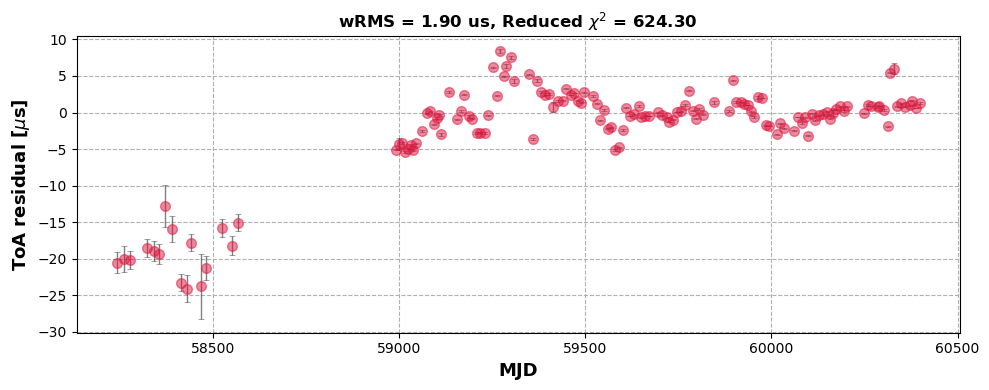

In [22]:
# Plotting the re-timed residuals
print(f'Plotting the post-fit ToA residuals')
fig = plt.figure(figsize=(10, 4), dpi=100)
plt.errorbar(toas, prenoise_timing_resids_fitted.time_resids.to(u.us), yerr=toaerrs, fmt='o', ms=7, c='crimson', alpha=0.5, \
             elinewidth=1.0, capsize=2, capthick=0.5, ecolor='k')
plt.ticklabel_format(useOffset=False)
plt.grid(ls='dashed')
plt.xlabel(f'MJD', fontweight='bold', fontsize=13)
plt.ylabel(rf'ToA residual [$\mu$s]', fontweight='bold', fontsize=13)
# fig.suptitle(f'{psrname} fitted timing residuals', fontweight='bold', fontsize=16)
plt.title(rf'wRMS = {prenoise_timing_resids_fitted.rms_weighted():.2f}, '+
          rf'Reduced $\chi^2$ = {combined_timing_resids_fitted.reduced_chi2:.2f}', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{outdir}/{psrname}.fitted.ToAres.pdf')

Plotting the post-fit DM residuals


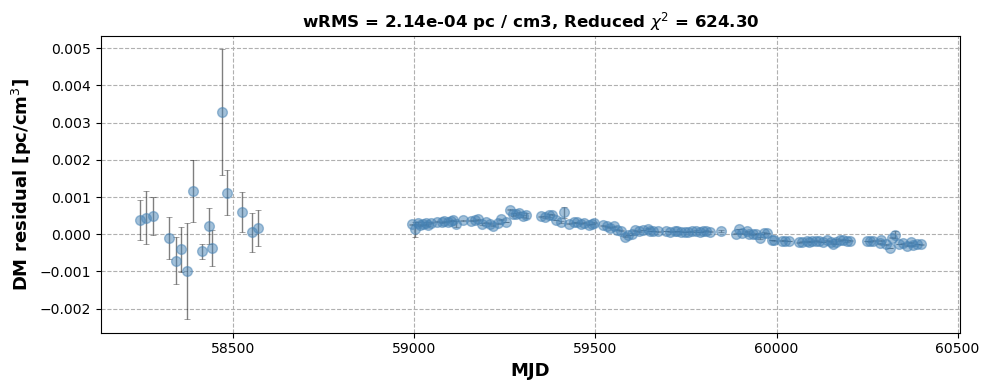

In [23]:
print(f'Plotting the post-fit DM residuals')
fig = plt.figure(figsize=(10, 4), dpi=100)
plt.errorbar(toas, prenoise_dm_resids_fitted.resids, yerr=dmerrs, fmt='o', ms=7, c='steelblue', alpha=0.5, \
             elinewidth=1.0, capsize=2, capthick=0.5, ecolor='k')
plt.ticklabel_format(useOffset=False)
plt.grid(ls='dashed')
plt.xlabel(f'MJD', fontweight='bold', fontsize=13)
plt.ylabel(rf'DM residual [pc/cm$^3$]', fontweight='bold', fontsize=13)
# fig.suptitle(f'{psrname} fitted DM residuals', fontweight='bold', fontsize=16)
plt.title(rf'wRMS = {prenoise_dm_resids_fitted.rms_weighted():.2e}, '+
          rf'Reduced $\chi^2$ = {combined_timing_resids_fitted.reduced_chi2:.2f}', fontweight='bold')
plt.tight_layout()
plt.savefig(f'{outdir}/{psrname}.fitted.DMres.pdf')

In [24]:
# Creating normalised residuals for Gaussianity test
prenoise_timing_resids_fitted_normalised = prenoise_timing_resids_fitted.time_resids.to(u.us)/toaerrs
prenoise_dm_resids_fitted_normalised = prenoise_dm_resids_fitted.resids/dmerrs

stat_toares, pval_toares = sp.stats.shapiro(prenoise_timing_resids_fitted_normalised)
stat_dmres, pval_dmres = sp.stats.shapiro(prenoise_dm_resids_fitted_normalised)

print(f'\nShapiro-Wilk test results for ToA residuals : \n\t Statistic = {stat_toares:.4e}, \tP-value = {pval_toares:.4e}\n')
print(f'Shapiro-Wilk test results for DM residuals : \n\t Statistic = {stat_dmres:.4e}, \tP-value = {pval_dmres:.4e}\n')


Shapiro-Wilk test results for ToA residuals : 
	 Statistic = 9.4811e-01, 	P-value = 4.2783e-05

Shapiro-Wilk test results for DM residuals : 
	 Statistic = 9.7725e-01, 	P-value = 1.9424e-02



For fully Gaussian residuals **the p-value must be greater than 0.5 and the statistic should be close to 1**.

However, in reality, it should be noted that it can almost never be obtained without SPNA.

Plotting the distribution of normalised ToA residuals


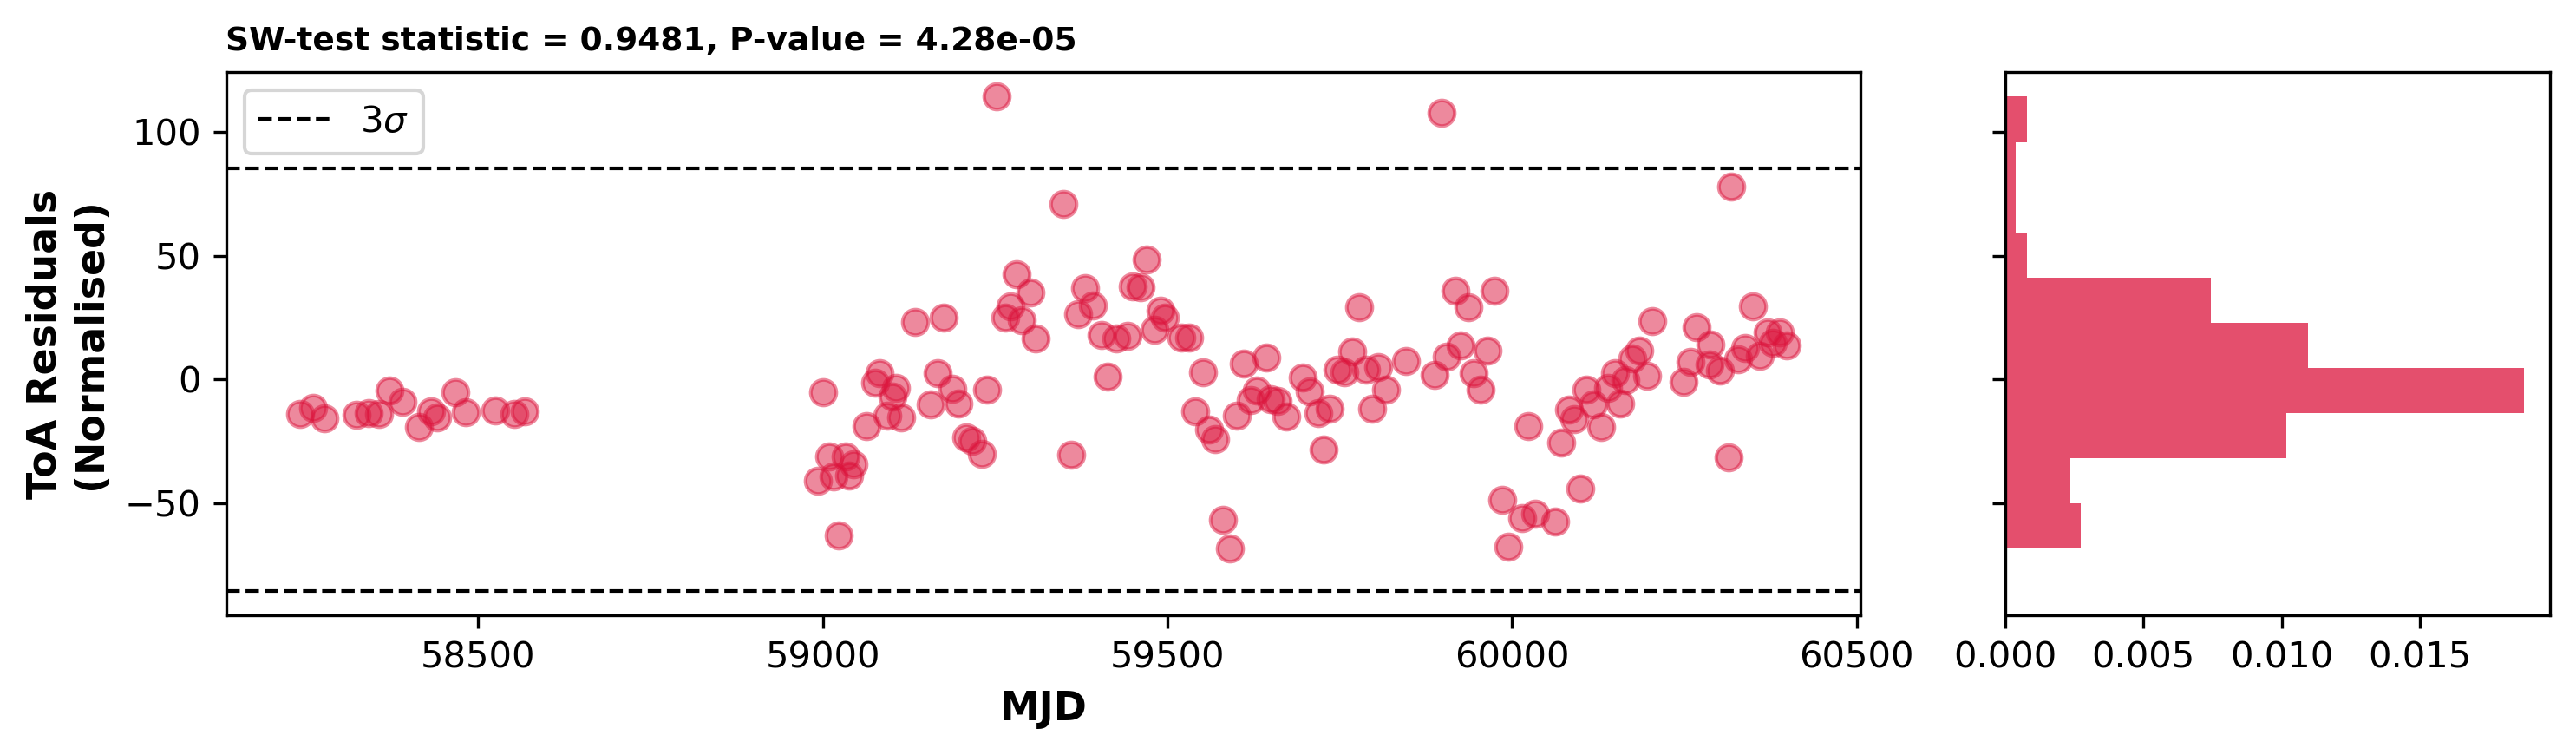

In [25]:
# Histogram of normalised post-noise ToA and DM residuals
print(f'Plotting the distribution of normalised ToA residuals')
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=False, sharey=True, width_ratios=[3, 1])
fig.subplots_adjust(wspace=0, hspace=0)
axes[0].scatter(toas, prenoise_timing_resids_fitted_normalised, c='crimson', alpha=0.5, s=50)
axes[0].axhline(3*np.std(prenoise_timing_resids_fitted_normalised), ls='dashed', lw=1.0, color='k', label=r'$3\sigma$')
axes[0].axhline(-3*np.std(prenoise_timing_resids_fitted_normalised), ls='dashed', lw=1.0, color='k')
axes[1].hist(prenoise_timing_resids_fitted_normalised, bins=10, color='crimson', alpha=0.75, orientation='horizontal', density=True)
axes[0].set_xlabel('MJD', fontsize=11, fontweight='bold')
axes[0].set_ylabel(f'ToA Residuals\n(Normalised)', fontsize=11, fontweight='bold')
axes[0].legend(loc='upper left')
axes[0].set_title(f'SW-test statistic = {stat_toares:.4f}, P-value = {pval_toares:.2e}', 
                  fontweight='bold', fontsize=9, x=0.26)
plt.tight_layout()
plt.savefig(f'{outdir}/{psrname}.fitted.normalised.ToAres.pdf')

Plotting the distribution of normalised DM residuals


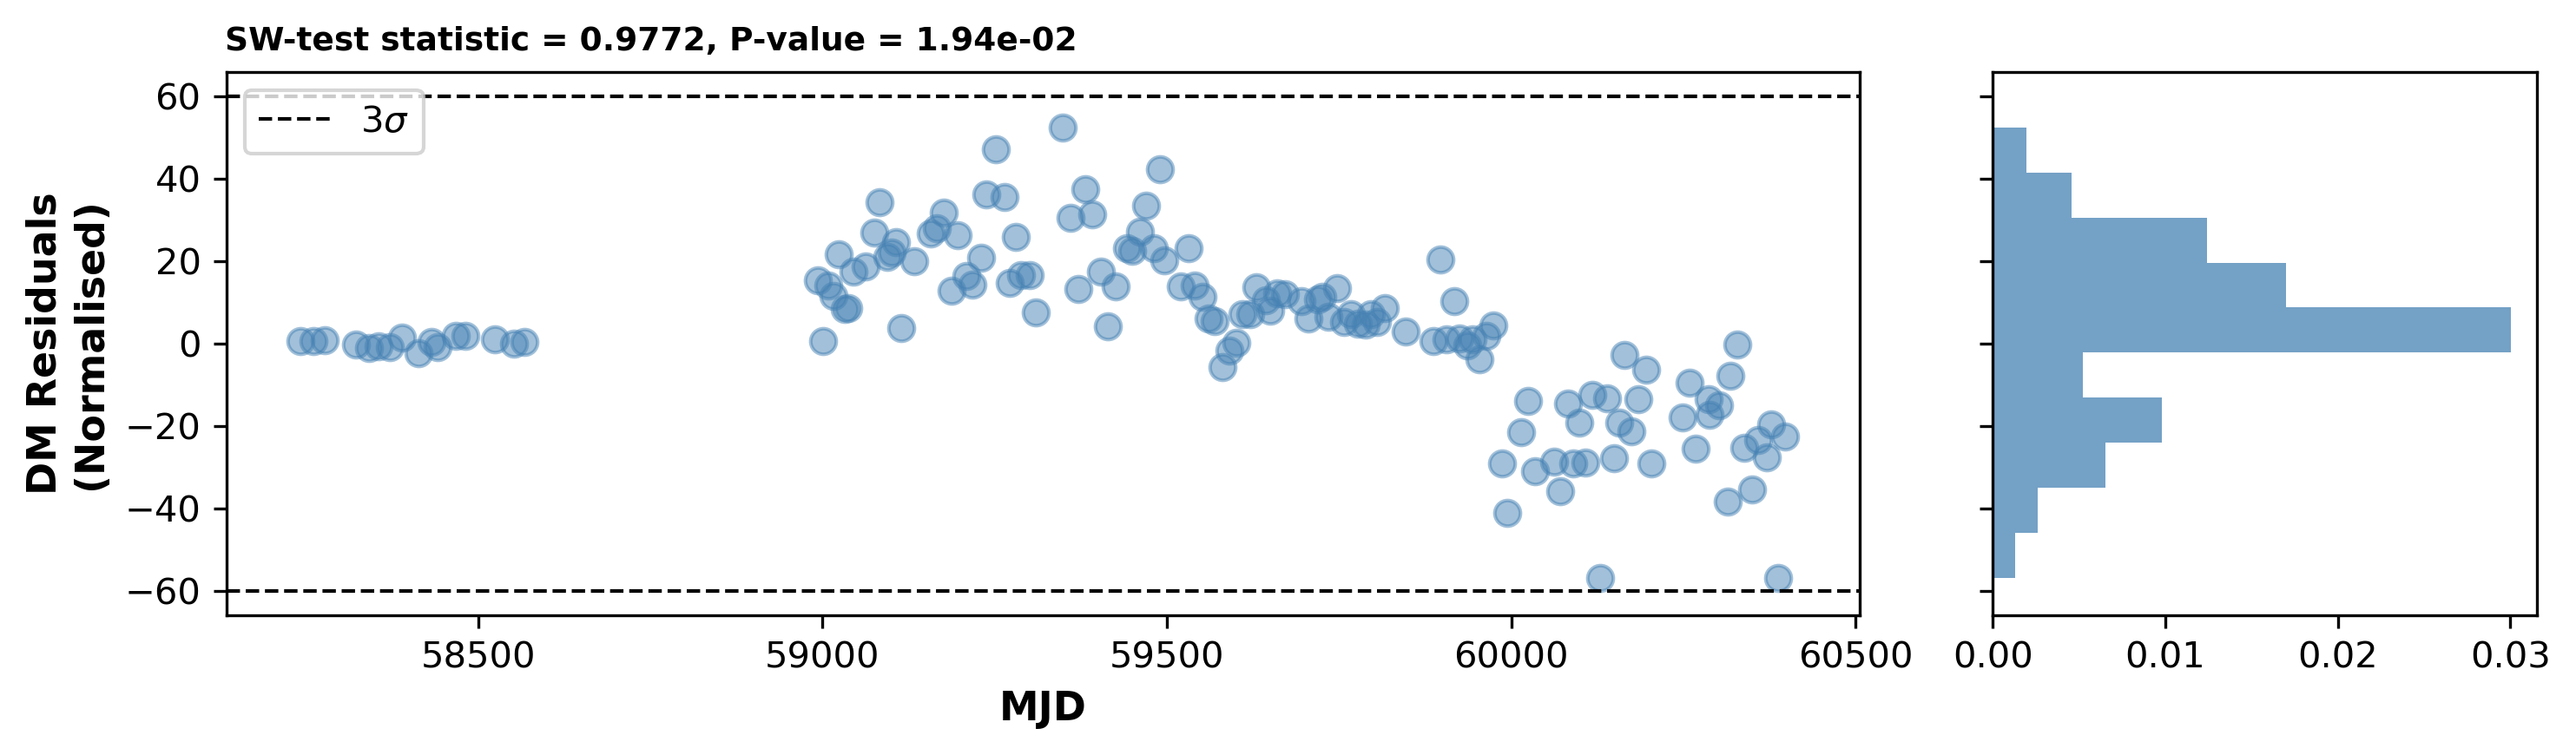

In [26]:
print(f'Plotting the distribution of normalised DM residuals')
fig, axes = plt.subplots(1, 2, figsize=(10, 3), sharex=False, sharey=True, width_ratios=[3, 1])
fig.subplots_adjust(wspace=0, hspace=0)
axes[0].scatter(toas, prenoise_dm_resids_fitted_normalised, c='steelblue', alpha=0.5, s=50)
axes[0].axhline(3*np.std(prenoise_dm_resids_fitted_normalised), ls='dashed', lw=1.0, color='k', label=r'$3\sigma$')
axes[0].axhline(-3*np.std(prenoise_dm_resids_fitted_normalised), ls='dashed', lw=1.0, color='k')
axes[1].hist(prenoise_dm_resids_fitted_normalised, bins=10, color='steelblue', alpha=0.75, orientation='horizontal', density=True)
axes[0].set_xlabel('MJD', fontsize=11, fontweight='bold')
axes[0].set_ylabel(f'DM Residuals\n(Normalised)', fontsize=11, fontweight='bold')
axes[0].legend(loc='upper left')
axes[0].set_title(f'SW-test statistic = {stat_dmres:.4f}, P-value = {pval_dmres:.2e}', 
                  fontweight='bold', fontsize=9, x=0.26)
plt.tight_layout()
plt.savefig(f'{outdir}/{psrname}.fitted.normalised.DMres.pdf')

In [31]:
# Generating the 3-sigma cutoff ToAs and DMs
tres_idxs = np.where(np.abs(prenoise_timing_resids_fitted_normalised) > 3*np.std(prenoise_timing_resids_fitted_normalised))[0]
dmres_idxs = np.where(np.abs(prenoise_dm_resids_fitted_normalised) > 3*np.std(prenoise_dm_resids_fitted_normalised))[0]

if tres_idxs.size:
    np.savetxt(f'{outdir}/{psrname}.pre-noise.NormToAres.3-sigma.txt', 
               np.array([toas[tres_idxs], prenoise_timing_resids_fitted_normalised[tres_idxs]]).T, fmt='%5.8f %s')
    print(f'Post-fit ToA outliers (normalised residuals) : {toas[tres_idxs]}\n')
else:
    print(f'No ToA outliers post-fit\n')

if dmres_idxs.size:
    np.savetxt(f'{outdir}/{psrname}.pre-noise.NormDMres.3-sigma.txt', 
               np.array([toas[dmres_idxs], prenoise_dm_resids_fitted_normalised[dmres_idxs]]).T, fmt='%5.8f %s')
    print(f'Post-fit DM outliers (normalised residuals) : {toas[dmres_idxs]}\n')
else:
    print(f'No DM outliers post-fit\n')

# Generating common ToA and DM post-noise outliers
common_idxs = []
for idx in tres_idxs:
    if idx in dmres_idxs:
        common_idxs.append(idx)

common_idxs = np.array(common_idxs)
if common_idxs.size:
    np.savetxt(f'{outdir}/{psrname}.pre-noise.NormToAres+NormDMres.3-sigma.txt', 
               np.array([toas[common_idxs], 
                         prenoise_timing_resids_fitted_normalised[common_idxs], 
                         prenoise_dm_resids_fitted_normalised[common_idxs]]).T)
else:
    print(f'No common ToA and DM outliers post-fit\n')

Post-fit ToA outliers (normalised residuals) : [59252.12853012 59897.33940987] d

No DM outliers post-fit

No common ToA and DM outliers post-fit



**NOTE :** Make sure to save this notebook in a PDF format and share with Churchil once timing is done.

**Total 3 cases for timing :**

- Band 3 : `<psrname>.Band3.legacyPP.tim`, `<psrname>.Band3.mlan.tim`
- Band 3+5 : `<psrname>.Band3+5.legacyPP.tim`, `<psrname>.Band3+5.mlan.tim`
- Band 3 + Band 3+5 (concatenated tim files) : `<psrname>.Band3+35.legacyPP.tim`, `<psrname>.Band3+35.mlan.tim`

We should expect **similar timing solutions** for all the 3 cases of analyses.

**File name should be :** `<psrname>.<Band3/Band3+5/Band3+35>.<legacyPP/mlan>.wb.timing.pdf`

**Steps to create the PDF file :**

- Open a new terminal window (make sure `jupyter` is present in the environment along with `nbconvert` and `xelatex` support)
- Run the command : `jupyter nbconvert <path>/wb.pre-noise.timing.ipynb --to pdf --no-input`
- This will save a PDF file named : `wb.pre-noise.timing.pdf`
- Rename this file to `<psrname>.<Band3/Band3+5/Band3+35>.<legacyPP/mlan>.wb.timing.pdf`

*In case the file cannot be converted to PDF, please change the name of the notebook itself to* `<psrname>.<Band3/Band3+5/Band3+35>.<legacyPP/mlan>.wb.timing.ipynb` *and share it with Churchil.*

**IMPORTANT -- TBD after timing is done**

Go to https://github.com/inpta/InPTA.DR2/tree/main/DM12.par and compare the timing solution obtained with the NB timing analysis for your pulsar.

**NOTE :** This is the private InPTA DR2 repository, so in case the repository cannot be accessed, please mention it to Churchil.

- Parameters fitted for NB : `<add-inputs>`
- Parameters fitted for WB : `<add-inputs>`

### Visualising the parameter differences between pre-timing and post-timing solutions

The `timing_solution_visualisation_dr2wb.py` code gives an estimate of the parameter shifts and error ratios for fitted parameters, which are calculated in two approaches :

- Approach 1 : $$\Delta=\frac{p_1-p_0}{\sqrt{\sigma_1^2+\sigma_0^2}}\in\mathbb{R},\;\; \rho=\frac{max(\sigma_1,\sigma_0)}{min(\sigma_1,\sigma_0)}\geq1$$

- Approach 2 : $$\Delta=\frac{p_1-p_0}{\sigma_0}\in\mathbb{R},\;\; \rho=\frac{\sigma_1}{\sigma_0}\geq0$$

In both cases, $\{p_0,\sigma_0\}$ correspond to the parameter values and uncertainties in the pre-fit timing solution and $\{p_1,\sigma_1\}$ correspond to those in the post-fit timing solution. Therefore, approach 1 can be considered as a quality check to see if there is significant mismatch in the two uncertainties and whether or not the parameters have also changed significantly. On the other hand, approach 2 is a direct comparison relative to the pre-fit timing solution which aims at giving an understanding of how much the solution has changed after timing.

**NOTE :**

There are two cases where the obtained timing solution should be scrutinised before going ahead :

- When the error ratio is too large (beyond 10x)
    - The generated plot will have color in red, orange or green (while green is still okay, orange and red must be inspected)
- When shift is too large (either positive or negative)
    - The plot will have a very large horizontal span for that parameter
    - This should be inspected regardless the color we obtain in the first case


In [ ]:
cmd = f'python3 ./timing_solution_visualisation_dr2wb.py {parfile} {fitted_parfile} {outdir}'
try: os.system(cmd)
except Exception as e: print(e)

In [ ]:
for param in psr_model.fittable_params:
    print(param)